# EN3330 Assignment 03 — Plots

In [21]:
import numpy as np
import matplotlib.pyplot as plt

FIG_DIR = "figures"
plt.rcParams.update({
    "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 11, "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # one colour per curve
FEAS = "#ececec"                                               # shading for the feasible region

def L(mu, x):
    """Lagrangian L(mu, x) = x^2 + mu(1 - x)."""
    return x**2 + mu * (1 - x)

## Q1(a) — $L(\mu, x)$ for $\mu = 0, 1, 2, 3$ with minimizers $x(\mu) = \mu/2$

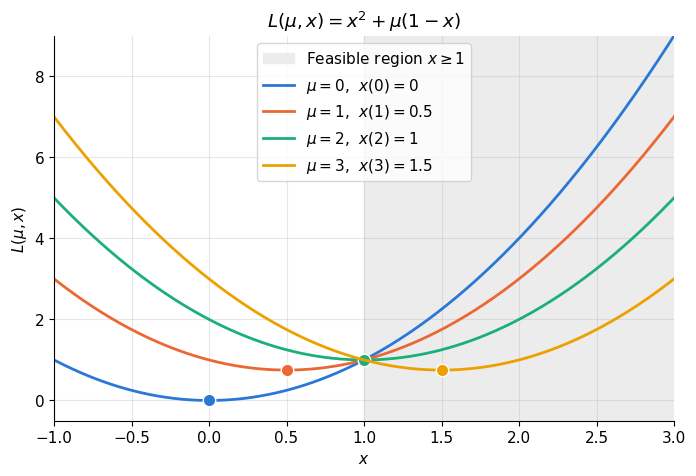

In [22]:
x = np.linspace(-1, 3, 400)

fig, ax = plt.subplots(figsize=(8, 5))
ax.axvspan(1, 3, color=FEAS, label=r"Feasible region $x \geq 1$")
for i, mu in enumerate([0, 1, 2, 3]):
    xm = mu / 2                                                 # minimizer x(mu)
    ax.plot(x, L(mu, x), color=C[i], label=fr"$\mu={mu}$,  $x({mu})={xm:g}$")
    ax.plot(xm, L(mu, xm), "o", color=C[i], ms=9, mec="white")
ax.set(xlim=(-1, 3), ylim=(-0.5, 9), xlabel="$x$", ylabel=r"$L(\mu, x)$",
       title=r"$L(\mu, x) = x^2 + \mu(1 - x)$")
ax.legend(loc="upper center")
plt.savefig(f"{FIG_DIR}/q1_a.png")
plt.show()

## Q1(b) — Dual function $d(\mu) = \mu - \mu^2/4$

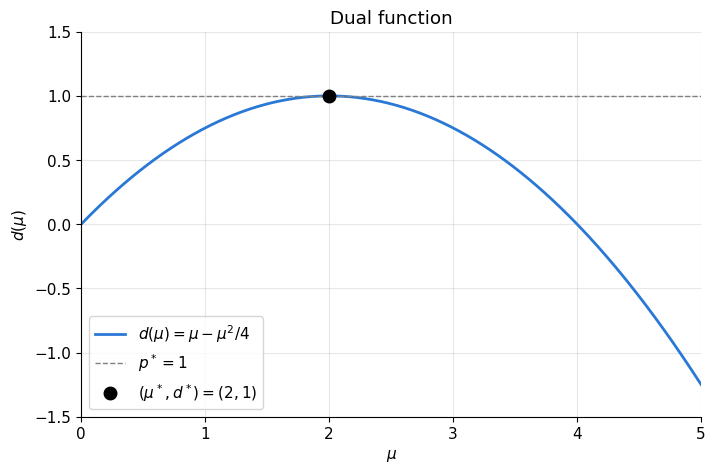

In [23]:
mu = np.linspace(0, 5, 400)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(mu, mu - mu**2 / 4, color=C[0], label=r"$d(\mu) = \mu - \mu^2/4$")
ax.axhline(1, color="gray", ls="--", lw=1, label=r"$p^* = 1$")
ax.plot(2, 1, "o", color="black", ms=9, label=r"$(\mu^*, d^*) = (2, 1)$")
ax.set(xlim=(0, 5), ylim=(-1.5, 1.5), xlabel=r"$\mu$", ylabel=r"$d(\mu)$", title="Dual function")
ax.legend(loc="lower left")
plt.savefig(f"{FIG_DIR}/q1_b.png")
plt.show()

## Q1(c) — Primal function $g(x) = \max_{\mu \geq 0} L(\mu, x)$ on $[-1, 3]$

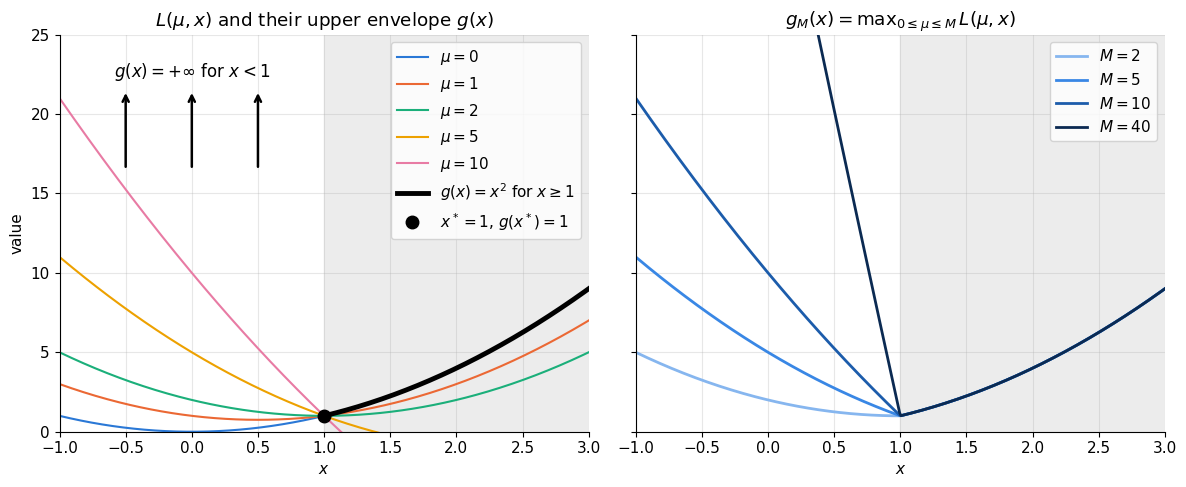

In [24]:
x = np.linspace(-1, 3, 400)
feas = x >= 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax in (ax1, ax2):
    ax.axvspan(1, 3, color=FEAS)
    ax.set(xlim=(-1, 3), ylim=(0, 25), xlabel="$x$")

# Left: curves L(mu, x) and their upper envelope g(x)
for i, mu in enumerate([0, 1, 2, 5, 10]):
    ax1.plot(x, L(mu, x), color=C[i], lw=1.5, label=fr"$\mu={mu}$")
ax1.plot(x[feas], x[feas]**2, color="black", lw=3.5, label=r"$g(x) = x^2$ for $x \geq 1$")
ax1.plot(1, 1, "o", color="black", ms=9, label=r"$x^* = 1$, $g(x^*) = 1$")
for xa in [-0.5, 0, 0.5]:                                      # arrows: g(x) goes to +infinity for x < 1
    ax1.annotate("", xy=(xa, 21.5), xytext=(xa, 16.5), arrowprops=dict(arrowstyle="->", lw=1.8))
ax1.text(0, 22.3, r"$g(x) = +\infty$ for $x < 1$", ha="center", fontsize=12)
ax1.set(ylabel="value", title=r"$L(\mu, x)$ and their upper envelope $g(x)$")
ax1.legend(loc="upper right")

# Right: capped maximum g_M(x) = x^2 + M max(1 - x, 0), which grows without bound for x < 1
for colr, M in zip(["#86b6ef", "#3987e5", "#1c5cab", "#0b2a52"], [2, 5, 10, 40]):
    ax2.plot(x, x**2 + M * np.maximum(1 - x, 0), color=colr, label=f"$M={M}$")
ax2.set(title=r"$g_M(x) = \mathrm{max}_{0 \leq \mu \leq M}\, L(\mu, x)$")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_c.png")
plt.show()

## Q2(a)(iv) — $L(\mu, x^*)$ against $\mu$ and $L(\mu^*, x)$ against $x$

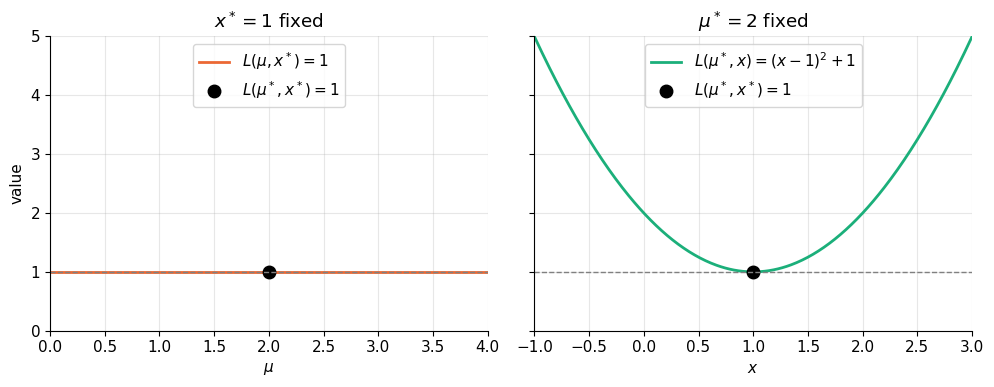

In [25]:
mu = np.linspace(0, 4, 400)
x = np.linspace(-1, 3, 400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax1.plot(mu, L(mu, 1), color=C[1], label=r"$L(\mu, x^*) = 1$")
ax1.plot(2, 1, "o", color="black", ms=9, label=r"$L(\mu^*, x^*) = 1$")
ax1.set(xlim=(0, 4), ylim=(0, 5), xlabel=r"$\mu$", ylabel="value", title=r"$x^* = 1$ fixed")

ax2.plot(x, L(2, x), color=C[2], label=r"$L(\mu^*, x) = (x-1)^2 + 1$")
ax2.plot(1, 1, "o", color="black", ms=9, label=r"$L(\mu^*, x^*) = 1$")
ax2.set(xlim=(-1, 3), xlabel="$x$", title=r"$\mu^* = 2$ fixed")

for ax in (ax1, ax2):
    ax.axhline(1, color="gray", ls="--", lw=1)
    ax.legend(loc="upper center")
plt.tight_layout(w_pad=2)
plt.savefig(f"{FIG_DIR}/q2_a.png")
plt.show()

## Q2(c) — Active constraint $x \geq 1$ vs inactive constraint $x \geq -1$

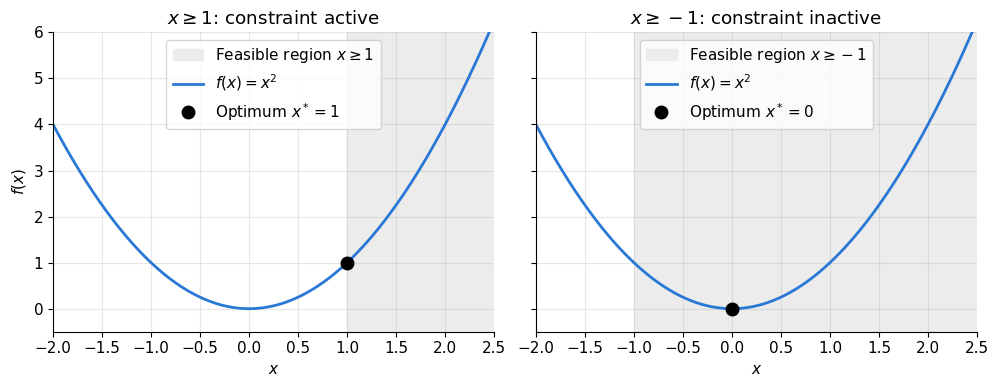

In [26]:
x = np.linspace(-2, 2.5, 400)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, b, xs, title in zip(axes, [1, -1], [1, 0],
                            [r"$x \geq 1$: constraint active", r"$x \geq -1$: constraint inactive"]):
    ax.axvspan(b, 2.5, color=FEAS, label=fr"Feasible region $x \geq {b}$")
    ax.plot(x, x**2, color=C[0], label=r"$f(x) = x^2$")
    ax.plot(xs, xs**2, "o", color="black", ms=9, label=fr"Optimum $x^* = {xs}$")
    ax.set(xlim=(-2, 2.5), ylim=(-0.5, 6), xlabel="$x$", title=title)
    ax.legend(loc="upper center")
axes[0].set_ylabel("$f(x)$")
plt.tight_layout(w_pad=2)
plt.savefig(f"{FIG_DIR}/q2_c_compare.png")
plt.show()

## Q2(c) — Dual functions for $x \geq 1$ and $x \geq -1$

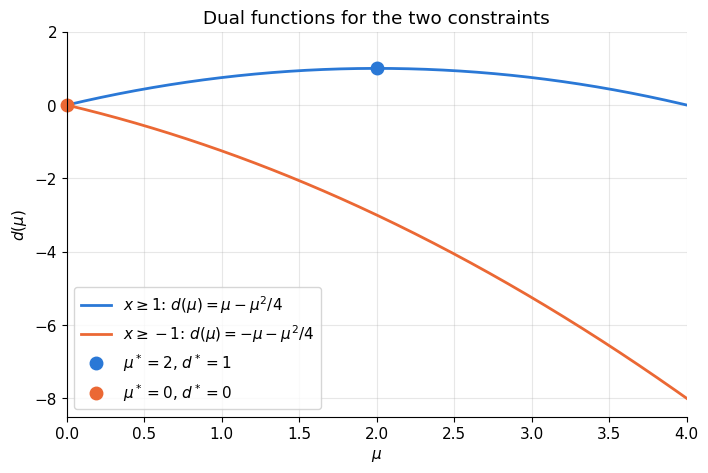

In [27]:
mu = np.linspace(0, 4, 400)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(mu, mu - mu**2 / 4, color=C[0], label=r"$x \geq 1$: $d(\mu) = \mu - \mu^2/4$")
ax.plot(mu, -mu - mu**2 / 4, color=C[1], label=r"$x \geq -1$: $d(\mu) = -\mu - \mu^2/4$")
ax.plot(2, 1, "o", color=C[0], ms=9, label=r"$\mu^* = 2$, $d^* = 1$")
ax.plot(0, 0, "o", color=C[1], ms=9, clip_on=False, label=r"$\mu^* = 0$, $d^* = 0$")
ax.set(xlim=(0, 4), ylim=(-8.5, 2), xlabel=r"$\mu$", ylabel=r"$d(\mu)$",
       title="Dual functions for the two constraints")
ax.legend(loc="lower left")
plt.savefig(f"{FIG_DIR}/q2_c_dual.png")
plt.show()

## Q3(b) — Lines $L(\mu, x)$ for $x = 0, 1, 2$, their lower envelope, and more lines approaching $d(\mu)$

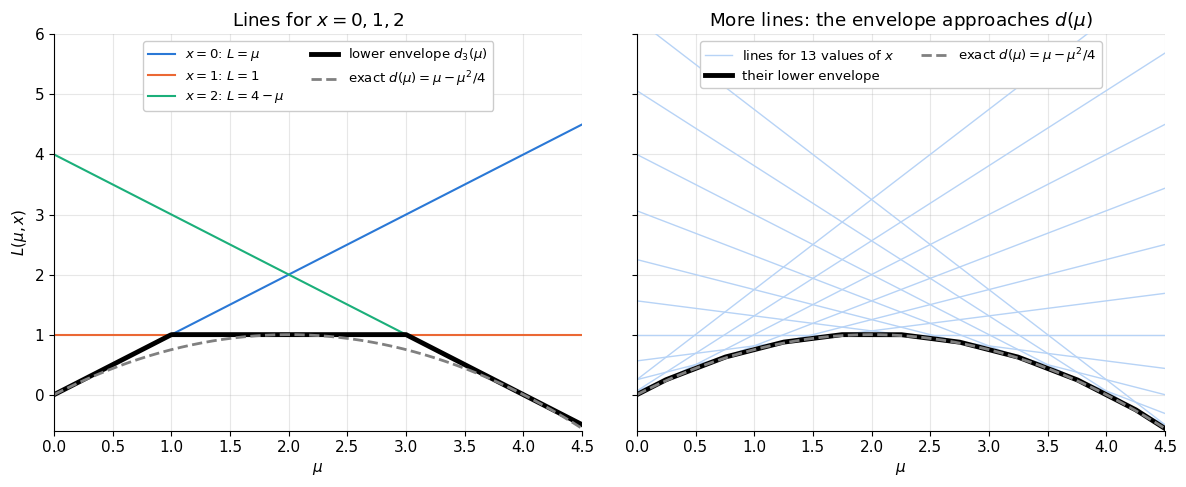

In [28]:
mu = np.linspace(0, 4.5, 400)
d = mu - mu**2 / 4                                              # exact dual function

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Left: the three lines for x = 0, 1, 2 and their lower envelope
lines = [L(mu, xv) for xv in [0, 1, 2]]                         # mu, 1, 4 - mu
for i, label in enumerate([r"$x=0$: $L = \mu$", r"$x=1$: $L = 1$", r"$x=2$: $L = 4 - \mu$"]):
    ax1.plot(mu, lines[i], color=C[i], lw=1.5, label=label)
ax1.plot(mu, np.min(lines, axis=0), color="black", lw=3.5, label=r"lower envelope $d_3(\mu)$")
ax1.set(ylabel=r"$L(\mu, x)$", title=r"Lines for $x = 0, 1, 2$")

# Right: more lines, so the lower envelope gets closer to d(mu)
many = [L(mu, xv) for xv in np.arange(-0.5, 2.51, 0.25)]         # 13 values of x
for k, line in enumerate(many):
    ax2.plot(mu, line, color="#b7d3f6", lw=1, label="lines for 13 values of $x$" if k == 0 else None)
ax2.plot(mu, np.min(many, axis=0), color="black", lw=3.5, label="their lower envelope")
ax2.set(title=r"More lines: the envelope approaches $d(\mu)$")

for ax in (ax1, ax2):
    ax.plot(mu, d, color="gray", ls="--", label=r"exact $d(\mu) = \mu - \mu^2/4$")
    ax.set(xlim=(0, 4.5), ylim=(-0.6, 6), xlabel=r"$\mu$")
    ax.legend(loc="upper center", ncol=2, fontsize=9.5, framealpha=1)
plt.tight_layout(w_pad=2)
plt.savefig(f"{FIG_DIR}/q3_b.png")
plt.show()